# Fraction of time on drug holiday: Bruchovsky cohort

Does the AT score, computed from the first treatment cycle only, predict how much of a patient's follow-up is spent off drug? Two versions of the endpoint are analysed:

* **Including the first cycle** (`Holiday_all`): 1 - time-weighted on-treatment fraction over the whole record. The fit sees cycle 1, so this endpoint is partly *in-window*.
* **Excluding the first cycle** (`Holiday_after_C1`): the same fraction from the start of cycle 2 onward. The fit never sees these data, so this is the *out-of-window* test.

The holiday fraction is observed for every patient with at least two cycles (all 72), so it needs no event definition and has no censoring.

**Method.** The first cycle (plus the first point of cycle 2) of each of the 72 patients is fitted with the corrected first-cycle protocol (`patients/first_cycle_fitting.py`: two free parameters, turnover and K; fitted K retained; constant kappa = 0.2 for the AT score).
Patients enter the analysis if the fitted model predicts progression under continuous treatment, the fit has R^2 > 0.5, and turnover is below the AT-score pole (where the score is not an ordered quantity).
The pre-specified comparisons are AT score vs `Holiday_all` and vs `Holiday_after_C1`; benchmark first-cycle PSA metrics are shown for context. 

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import scipy as sc
from scipy.stats import linregress, pearsonr, spearmanr, kendalltau, mannwhitneyu, rankdata
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

sys.path.append("../utils"); sys.path.append("../patients")
from myUtils import test_progression, LoadPatientData, GetPatientIDs, calc_delta_benefit, fraction_time_on_treatment
from plotUtils import PlotData
import first_cycle_fitting as fcf

In [2]:
# Defaults for plotting
try:
    plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
except Exception:
    plt.style.use("classic")
plt.rcParams["font.size"] = 12
plt.rcParams["figure.facecolor"] = "white"
BLUE, GREY = "#0044AA", "#777777"
OUT = "../analysis"      # tables and figures written here

In [3]:
data_path = "../patients/Bruchovsky_et_al/Complete_data"
patientIds = GetPatientIDs(data_path)
print("Loaded %d patient IDs" % len(patientIds))
KAPPA = 0.2              # constant kappa of the corrected protocol
POLE = 0.72

Loaded 72 patient IDs
AT-score pole (turnover at which calc_delta_benefit changes sign): 0.7200


## Patient datasets

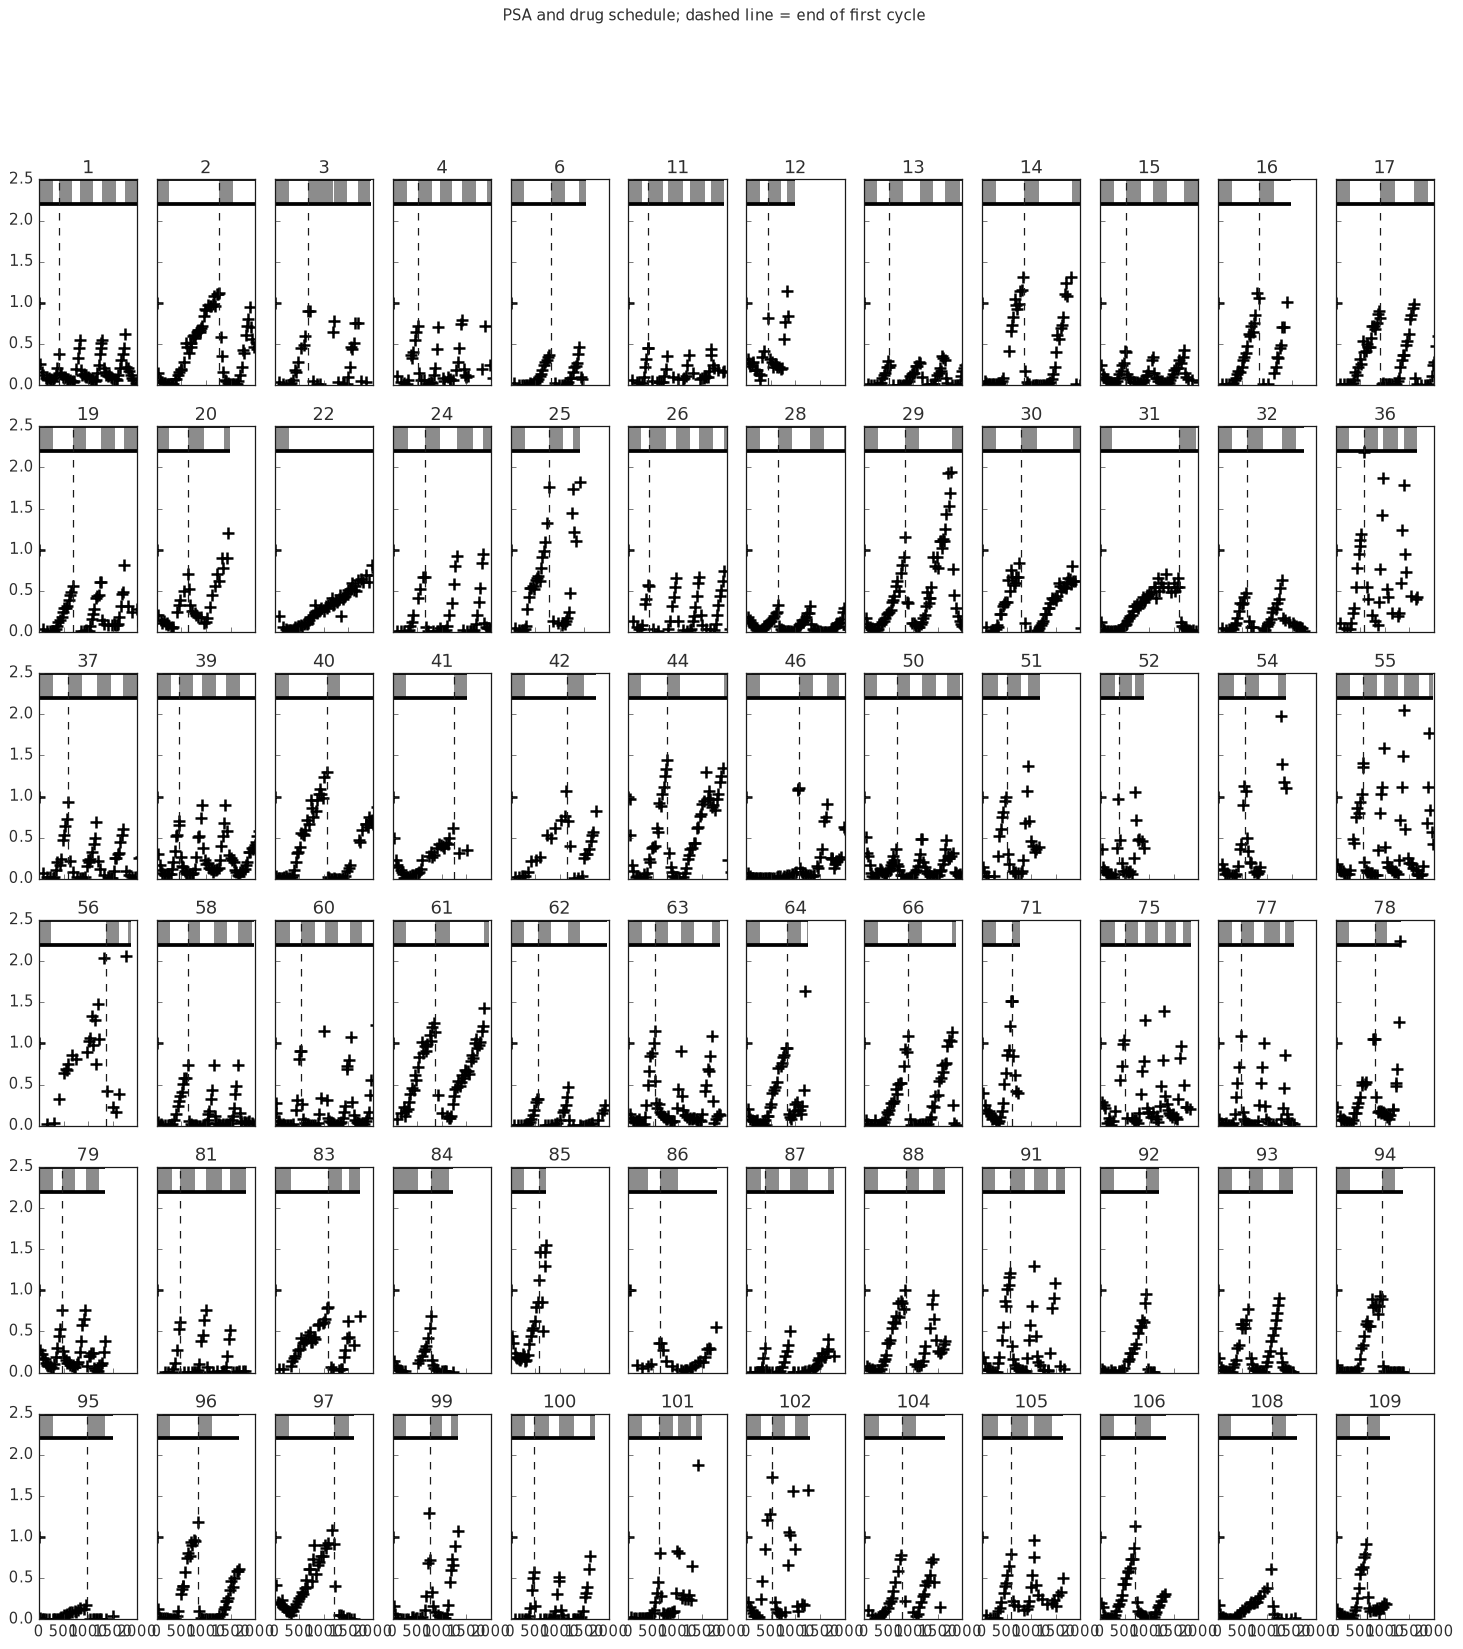

In [4]:
# PSA (normalised to the first measurement) and drug bar for every patient; dashed line = end of the first cycle (treatment restart)
def first_cycle_end(pid):
    d = LoadPatientData(pid, data_path)
    r = d.loc[d["CycleId"] == 2, "Time"]
    return float(r.iloc[0]) if len(r) else np.nan

fig, axs = plt.subplots(6, int((len(patientIds) + 5) / 6), figsize=(20, 20), sharey=True, sharex=True)
for i, pid in enumerate(patientIds):
    dataDf = LoadPatientData(pid, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=2.2, drugBarHeight=0.3)
    axs.flatten()[i].axvline(first_cycle_end(pid), color="k", ls="--", lw=1)
    axs.flatten()[i].set_title(pid); axs.flatten()[i].set_ylim(0, 2.5)
fig.suptitle("PSA and drug schedule; dashed line = end of first cycle", y=0.995)
fig.savefig(f"{OUT}/holiday_bruchovsky_patients.png", dpi=110); plt.show()

## Endpoints: fraction of time on holiday

`fraction_time_on_treatment` (in `utils/myUtils.py`) is the time-weighted on-treatment fraction, step-holding the drug state of the preceding reading.

| name | window | role |
|---|---|---|
| `Holiday_all` | whole record | primary, includes the fitted cycle |
| `Holiday_after_C1` | from the first row of cycle 2 onward | primary, out-of-window |
| `Holiday_C1` | first cycle only (to the restart) | control: it shares the data the model was fitted to |

In [5]:
def holiday_all(pid):
    return 1 - fraction_time_on_treatment(LoadPatientData(pid, data_path))

def holiday_cycle1(pid):
    d = LoadPatientData(pid, data_path)
    return 1 - fraction_time_on_treatment(d, t_end=first_cycle_end(pid))

def holiday_after_c1(pid):
    d = LoadPatientData(pid, data_path).dropna(subset=["DrugConcentration"]).reset_index()
    idx = d[d.CycleId == 1].index
    if len(idx) == 0: return np.nan
    d2 = d[d.index > idx[-1]]
    return 1 - fraction_time_on_treatment(d2) if len(d2) >= 2 else np.nan

rows = []
for pid in patientIds:
    d = LoadPatientData(pid, data_path)
    rows.append({"PatientId": pid, "Holiday_all": holiday_all(pid), "Holiday_after_C1": holiday_after_c1(pid),
                 "Holiday_C1": holiday_cycle1(pid), "Cycle1_length": first_cycle_end(pid), "TimeInTrial": float(d.Time.max()),
                 "N_cycles": int(d.CycleId.max())})
endpoints_df = pd.DataFrame(rows).set_index("PatientId")
print("Endpoints available for %d / %d patients" % (endpoints_df.Holiday_all.notna().sum(), len(endpoints_df)))
print(endpoints_df[["Holiday_all", "Holiday_after_C1", "Holiday_C1", "Cycle1_length", "TimeInTrial", "N_cycles"]].describe().round(3).to_string())

Endpoints available for 72 / 72 patients
       Holiday_all  Holiday_after_C1  Holiday_C1  Cycle1_length  TimeInTrial  N_cycles
count       72.000            72.000      72.000         72.000       72.000    72.000
mean         0.495             0.384       0.562        744.278     1725.889     3.181
std          0.136             0.173       0.152        301.371      386.187     0.954
min          0.160             0.000       0.198        383.000      728.000     2.000
25%          0.376             0.293       0.444        534.250     1486.500     2.000
50%          0.487             0.383       0.569        647.000     1752.000     3.000
75%          0.599             0.489       0.678        846.750     2063.750     4.000
max          0.818             0.728       0.864       2090.000     2284.000     5.000


Spearman between endpoints: all vs after C1 = 0.541 ; all vs C1 = 0.860 ; after C1 vs C1 = 0.176


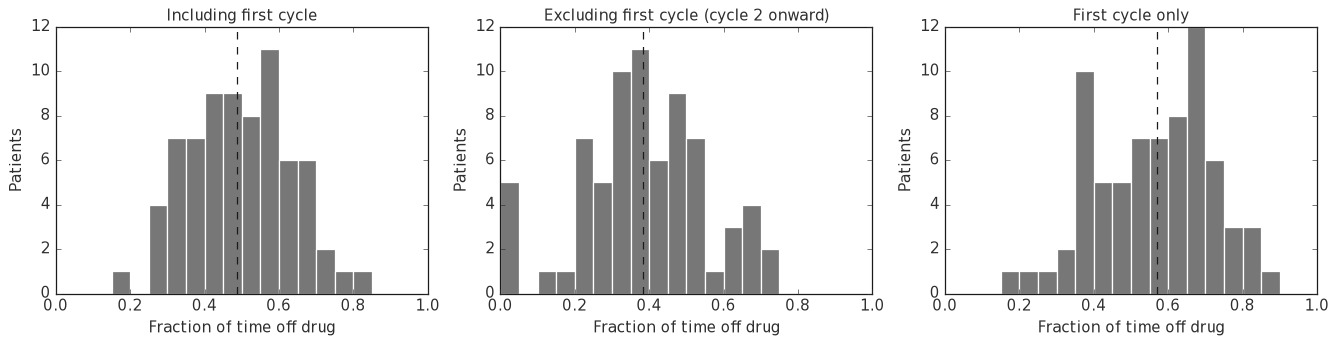

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, lab in zip(axs, ["Holiday_all", "Holiday_after_C1", "Holiday_C1"],
                        ["Including first cycle", "Excluding first cycle (cycle 2 onward)", "First cycle only"]):
    ax.hist(endpoints_df[col].dropna(), bins=np.linspace(0, 1, 21), color=GREY, edgecolor="w")
    ax.axvline(endpoints_df[col].median(), color="k", ls="--"); ax.set_title(lab, fontsize=12)
    ax.set_xlabel("Fraction of time off drug"); ax.set_ylabel("Patients")
fig.tight_layout(); fig.savefig(f"{OUT}/holiday_bruchovsky_endpoint_distributions.png", dpi=150); plt.show()
print("Spearman between endpoints: all vs after C1 = %.3f ; all vs C1 = %.3f ; after C1 vs C1 = %.3f" % (
    spearmanr(endpoints_df.Holiday_all, endpoints_df.Holiday_after_C1, nan_policy="omit")[0],
    spearmanr(endpoints_df.Holiday_all, endpoints_df.Holiday_C1, nan_policy="omit")[0],
    spearmanr(endpoints_df.Holiday_after_C1, endpoints_df.Holiday_C1, nan_policy="omit")[0]))

## Fit to first cycle only

Two parameters (turnover, K) are fitted per patient with the corrected protocol; priors `fR = 1e-5`, `cost = 0.1`, fixed `rS` and `dD`; data window = cycle 1 plus the first point of cycle 2.

In [7]:
fits = fcf.fit_cohort("Bruchovsky", fcf.COHORTS["Bruchovsky"])
print("fits: n=%d, model progresses in %d, median R^2 = %.3f, turnover at/above the pole in %d" % (
    len(fits), fits.Progression.sum(), fits.RSquared.median(), (fits.turnover >= POLE).sum()))

fits: n=72, model progresses in 57, median R^2 = 0.643, turnover at/above the pole in 3


## AT score and patient filters

In [8]:
def predict_ct_ttp(n_lim=None, **kwargs):
    # continuous-treatment time to resistant progression (absence of sensitive cells); used here only to require that the model progresses
    params = kwargs
    if n_lim is None: n_lim = params["n0"] * 1.2
    factor = params["rR"] - params["dR"]
    log_num = params["rR"] - factor * (params["K"] / params["R0"])
    log_den = params["rR"] - factor * (params["K"] / n_lim)
    return np.log(log_num / log_den) / factor

rows = []
for _, r in fits.iterrows():
    p = r.to_dict(); pid = int(p["PatientId"])
    if not p["Progression"]: continue
    try:
        ct = float(predict_ct_ttp(**p)); at = calc_delta_benefit(kappa=KAPPA, **p)
    except Exception:
        continue
    rows.append([pid, p["RSquared"], ct, at, p["turnover"]])
tab = pd.DataFrame(rows, columns=["PatientId", "RSquared", "CT_Perfect", "AT_Score", "turnover"])
tab = tab[tab["CT_Perfect"] > 0]                                    # model progresses under continuous treatment
poor_fit = tab[tab["RSquared"] <= 0.5]["PatientId"].tolist()
tab = tab[tab["RSquared"] > 0.5]                                    # good fits only
above_pole = tab[tab["turnover"] >= POLE]["PatientId"].tolist()
tab = tab[tab["turnover"] < POLE].reset_index(drop=True)            # AT score is ordered only below the pole
print("%d of %d patients retained (R^2 <= 0.5: %d; at/above the pole after the R^2 filter: %d)" % (len(tab), len(patientIds), len(poor_fit), len(above_pole)))

40 of 72 patients retained (R^2 <= 0.5: 17; at/above the pole after the R^2 filter: 0)


## Is the retained subset representative for the holiday endpoint?

Holiday fractions of retained vs excluded patients (Mann-Whitney).

In [9]:
inc = set(tab.PatientId); rows = []
for col in ["Holiday_all", "Holiday_after_C1"]:
    a = endpoints_df.loc[[p for p in patientIds if p in inc], col].dropna()
    b = endpoints_df.loc[[p for p in patientIds if p not in inc], col].dropna()
    u = mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"Endpoint": col, "N_retained": len(a), "Median_retained": a.median(), "N_excluded": len(b), "Median_excluded": b.median(), "Mann-Whitney P": u.pvalue})
selection_df = pd.DataFrame(rows); print(selection_df.round(3).to_string(index=False))

        Endpoint  N_retained  Median_retained  N_excluded  Median_excluded  Mann-Whitney P
     Holiday_all          40            0.447          32            0.559           0.011
Holiday_after_C1          40            0.394          32            0.378           0.790


## Benchmark PSA-based metrics

First-cycle metrics computed for the same patients: baseline PSA, nadir, time to nadir, PSA velocity and PSA doubling time during the off-treatment regrowth.

In [10]:
def _pick_psa_column(df):
    if "PSA_raw" in df.columns and df["PSA_raw"].notna().sum() > 0:
        return "PSA_raw"
    return "PSA"

def _safe_linregress(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y); x = x[mask]; y = y[mask]
    if len(x) < 2: return np.nan, np.nan, np.nan
    if np.allclose(x, x[0]) or np.allclose(y, y[0]): return np.nan, np.nan, np.nan
    res = linregress(x, y)
    return res.slope, res.intercept, res.pvalue

def get_first_cycle_df(patient_id, data_path):
    df = LoadPatientData(patient_id, data_path).copy().sort_values("Time").reset_index(drop=True)
    c1 = df[df["CycleId"] == 1].copy()
    return c1.sort_values("Time").reset_index(drop=True) if len(c1) > 0 else df

def compute_first_cycle_metrics(patient_id, data_path):
    c1 = get_first_cycle_df(patient_id, data_path)
    psa_col = _pick_psa_column(c1)
    c1v = c1[["Time", psa_col, "DrugConcentration"]].dropna(subset=["Time", psa_col]).sort_values("Time")
    c1v = c1v.groupby("Time", as_index=False).mean(numeric_only=True)
    out = {"PatientId": patient_id, "Baseline_Tumor_Burden": np.nan, "PSA_Nadir": np.nan, "Time_to_Nadir": np.nan,
           "PSA_Velocity_per_day": np.nan, "PSA_Doubling_Time_days": np.nan}
    if len(c1v) == 0: return out
    t0 = float(c1v["Time"].iloc[0]); out["Baseline_Tumor_Burden"] = float(c1v[psa_col].iloc[0])
    k = int(np.nanargmin(c1v[psa_col].to_numpy(dtype=float))); t_nadir = float(c1v["Time"].iloc[k])
    out["PSA_Nadir"] = float(c1v[psa_col].iloc[k]); out["Time_to_Nadir"] = t_nadir - t0
    reg = c1v[c1v["Time"] >= t_nadir].copy()
    off = reg[reg["DrugConcentration"].fillna(0.0) <= 0].copy()
    if len(off) >= 2: reg = off
    if len(reg) < 2: return out
    x = reg["Time"].to_numpy(dtype=float); y = reg[psa_col].to_numpy(dtype=float)
    out["PSA_Velocity_per_day"] = _safe_linregress(x, y)[0]
    pos = y > 0
    if np.sum(pos) >= 2:
        slope_log = _safe_linregress(x[pos], np.log(y[pos]))[0]
        out["PSA_Doubling_Time_days"] = np.log(2.0) / slope_log if np.isfinite(slope_log) and slope_log > 0 else np.nan
    return out

metrics_df = pd.DataFrame([compute_first_cycle_metrics(pid, data_path) for pid in patientIds]).sort_values("PatientId").reset_index(drop=True)
bench = pd.merge(metrics_df, tab, on="PatientId", how="inner").merge(endpoints_df.reset_index(), on="PatientId", how="left")
print(bench.shape)

(40, 16)


## Correlation report: AT score and PSA metrics vs fraction of time on holiday

In [11]:
def spearman_boot_ci(x, y, n=5000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(x, float); y = np.asarray(y, float); m = len(x); out = []
    for _ in range(n):
        i = rng.integers(0, m, m)
        if np.ptp(x[i]) == 0 or np.ptp(y[i]) == 0: continue
        out.append(spearmanr(x[i], y[i])[0])
    return np.percentile(out, [2.5, 97.5])

def correlation_report(df, metric_cols, target_cols):
    rows = []
    for m in metric_cols:
        for t in target_cols:
            sub = df[[m, t]].dropna(); n = len(sub)
            if n < 3:
                rows.append({"Metric": m, "Target": t, "N": n}); continue
            x = sub[m].to_numpy(dtype=float); y = sub[t].to_numpy(dtype=float)
            pr, pp = pearsonr(x, y); sr, sp = spearmanr(x, y); kt, kp = kendalltau(x, y); lo, hi = spearman_boot_ci(x, y)
            rows.append({"Metric": m, "Target": t, "N": n, "Pearson_r": pr, "Pearson_R2": pr ** 2, "Pearson_p": pp,
                         "Spearman_rho": sr, "Spearman_p": sp, "Spearman_CI95_lo": lo, "Spearman_CI95_hi": hi,
                         "Kendall_tau": kt, "Kendall_p": kp})
    return pd.DataFrame(rows)

metric_cols = ["AT_Score", "PSA_Doubling_Time_days", "PSA_Nadir", "Time_to_Nadir", "PSA_Velocity_per_day", "Baseline_Tumor_Burden"]
target_cols = ["Holiday_all", "Holiday_after_C1"]
corr = correlation_report(bench, metric_cols, target_cols)
print("=== Bruchovsky, corrected protocol (N = %d patients) ===" % len(bench))
print(corr.sort_values(["Target", "Metric"]).round(4).to_string(index=False))
corr.to_csv(f"{OUT}/holiday_bruchovsky_correlation_report.csv", index=False)

=== Bruchovsky, corrected protocol (N = 40 patients) ===
                Metric           Target  N  Pearson_r  Pearson_R2  Pearson_p  Spearman_rho  Spearman_p  Spearman_CI95_lo  Spearman_CI95_hi  Kendall_tau  Kendall_p
              AT_Score Holiday_after_C1 40     0.2376      0.0565     0.1398        0.3667      0.0199            0.0816            0.6023       0.2553     0.0204
 Baseline_Tumor_Burden Holiday_after_C1 40     0.1173      0.0138     0.4710       -0.0102      0.9500           -0.3477            0.3326      -0.0013     0.9907
PSA_Doubling_Time_days Holiday_after_C1 40     0.2317      0.0537     0.1502        0.2515      0.1175           -0.0752            0.5403       0.1783     0.1053
             PSA_Nadir Holiday_after_C1 40    -0.1520      0.0231     0.3492       -0.1943      0.2297           -0.4993            0.1450      -0.1502     0.2029
  PSA_Velocity_per_day Holiday_after_C1 40    -0.2543      0.0647     0.1134       -0.2312      0.1511           -0.5132        

`Holiday_all` partly shares its data with the fit (the first cycle); `Holiday_after_C1` does not. With 6 metrics x 2 endpoints only the AT-score rows were pre-specified.

## Scatter plots: AT score vs holiday fraction

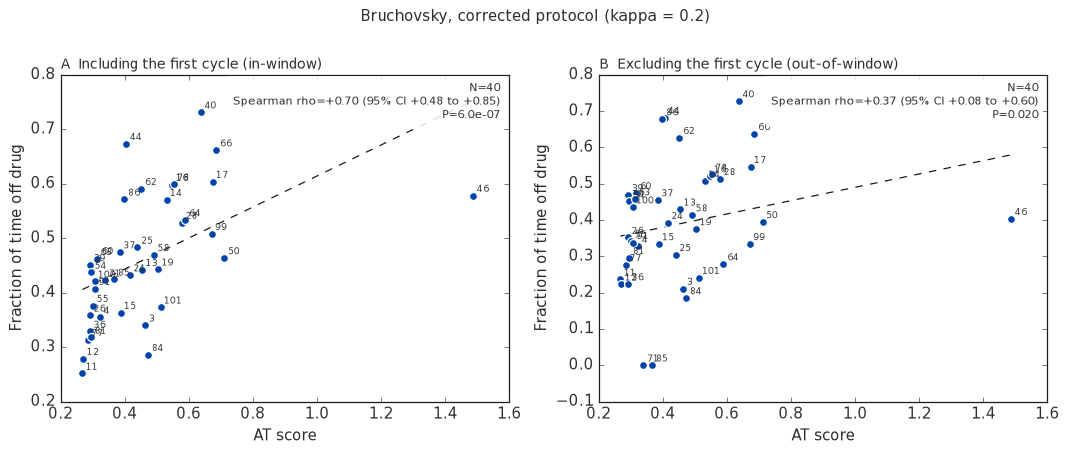

In [12]:
def scatter_panel(ax, df, xcol, ycol, color, title):
    sub = df[["PatientId", xcol, ycol]].dropna()
    rho, p = spearmanr(sub[xcol], sub[ycol]); lo, hi = spearman_boot_ci(sub[xcol], sub[ycol])
    ax.scatter(sub[xcol], sub[ycol], color=color, s=40, zorder=3, edgecolor="w")
    sl = linregress(sub[xcol], sub[ycol]); xs = np.linspace(sub[xcol].min(), sub[xcol].max(), 50)
    ax.plot(xs, sl.intercept + sl.slope * xs, color="k", lw=1, ls="--", zorder=2)
    for _, r in sub.iterrows(): ax.annotate(int(r.PatientId), (r[xcol], r[ycol]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(title, fontsize=11, loc="left"); ax.set_xlabel("AT score"); ax.set_ylabel("Fraction of time off drug")
    ax.text(0.98, 0.98, "N=%d\nSpearman rho=%+.2f (95%% CI %+.2f to %+.2f)\nP=%s" % (len(sub), rho, lo, hi, ("%.1e" % p) if p < 1e-3 else ("%.3f" % p)),
            transform=ax.transAxes, fontsize=9, va="top", ha="right", bbox=dict(fc="w", ec="none", alpha=.85))

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
scatter_panel(axs[0], bench, "AT_Score", "Holiday_all", BLUE, "A  Including the first cycle (in-window)")
scatter_panel(axs[1], bench, "AT_Score", "Holiday_after_C1", BLUE, "B  Excluding the first cycle (out-of-window)")
fig.suptitle("Bruchovsky, corrected protocol (kappa = 0.2)", y=1.0); fig.tight_layout(); fig.savefig(f"{OUT}/holiday_bruchovsky_scatter.png", dpi=150); plt.show()

## Comparison with the other PSA-based metrics

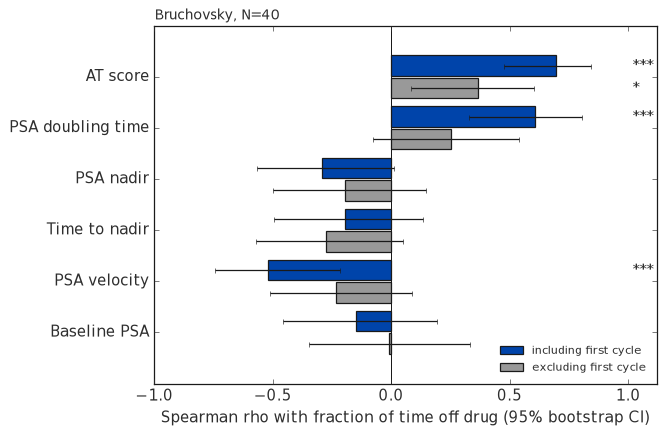

In [13]:
labels = {"AT_Score": "AT score", "PSA_Doubling_Time_days": "PSA doubling time", "PSA_Nadir": "PSA nadir",
          "Time_to_Nadir": "Time to nadir", "PSA_Velocity_per_day": "PSA velocity", "Baseline_Tumor_Burden": "Baseline PSA"}
fig, ax = plt.subplots(figsize=(7.5, 5)); ypos = np.arange(len(metric_cols))[::-1]
for off, tgt, c in ((0.22, "Holiday_all", BLUE), (-0.22, "Holiday_after_C1", "#999999")):
    s = corr[corr.Target == tgt].set_index("Metric").loc[metric_cols]
    ax.barh(ypos + off, s.Spearman_rho, height=0.4, color=c, label={"Holiday_all": "including first cycle", "Holiday_after_C1": "excluding first cycle"}[tgt])
    ax.errorbar(s.Spearman_rho, ypos + off, xerr=[s.Spearman_rho - s.Spearman_CI95_lo, s.Spearman_CI95_hi - s.Spearman_rho], fmt="none", ecolor="k", lw=1, capsize=2)
    for y_, p_ in zip(ypos + off, s.Spearman_p):
        if p_ < 0.05: ax.text(1.02, y_, "*" if p_ >= .01 else "**" if p_ >= .001 else "***", va="center", fontsize=11)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(ypos); ax.set_yticklabels([labels[m] for m in metric_cols]); ax.set_xlim(-1, 1.12)
ax.set_xlabel("Spearman rho with fraction of time off drug (95% bootstrap CI)"); ax.set_title("Bruchovsky, N=%d" % len(bench), fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower right"); fig.tight_layout(); fig.savefig(f"{OUT}/holiday_bruchovsky_spearman_bars.png", dpi=150); plt.show()

## Rank regression and partial correlations

All variables are rank-transformed and standardised, so regression coefficients are standardised rank betas (comparable to Spearman). Partial Spearman correlations ask whether the AT score still carries information once quantities that mechanically relate to the holiday fraction are held fixed:
the holiday fraction **within the fitted cycle**, the first-cycle length, and the total follow-up.

In [14]:
def rank_ols(df, y, xs):
    Z = df[xs + [y]].dropna(); R = Z.apply(rankdata); R = (R - R.mean()) / R.std(ddof=1)
    X = np.column_stack([np.ones(len(R)), R[xs].values]); yv = R[y].values
    beta = np.linalg.lstsq(X, yv, rcond=None)[0]; resid = yv - X @ beta; dof = len(yv) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X); se = np.sqrt(np.diag(cov)); tt = beta / se
    return pd.DataFrame({"beta": beta[1:], "lo": (beta - sc.stats.t.ppf(.975, dof) * se)[1:], "hi": (beta + sc.stats.t.ppf(.975, dof) * se)[1:],
                         "p": (2 * sc.stats.t.sf(abs(tt), dof))[1:]}, index=xs), len(yv)

cov_cols = ["Baseline_Tumor_Burden", "PSA_Nadir", "Time_to_Nadir", "PSA_Doubling_Time_days", "AT_Score"]
rr = []
for tgt in ["Holiday_all", "Holiday_after_C1"]:
    multi, n_m = rank_ols(bench, tgt, cov_cols)
    for cvar in cov_cols:
        uni, n_u = rank_ols(bench, tgt, [cvar])
        rr.append({"Endpoint": tgt, "Variable": labels[cvar], "N_uni": n_u, "Univariable beta": uni.beta.iloc[0], "Uni CI lo": uni.lo.iloc[0],
                   "Uni CI hi": uni.hi.iloc[0], "Uni p": uni.p.iloc[0], "N_multi": n_m, "Multivariable beta": multi.loc[cvar, "beta"], "Multi p": multi.loc[cvar, "p"]})
rank_reg_df = pd.DataFrame(rr); print(rank_reg_df.round(3).to_string(index=False)); rank_reg_df.to_csv(f"{OUT}/holiday_bruchovsky_rank_regression.csv", index=False)

        Endpoint          Variable  N_uni  Univariable beta  Uni CI lo  Uni CI hi  Uni p  N_multi  Multivariable beta  Multi p
     Holiday_all      Baseline PSA     40            -0.148     -0.472      0.177  0.363       40              -0.065    0.697
     Holiday_all         PSA nadir     40            -0.292     -0.606      0.022  0.068       40              -0.165    0.393
     Holiday_all     Time to nadir     40            -0.195     -0.517      0.127  0.227       40               0.022    0.866
     Holiday_all PSA doubling time     40             0.608      0.347      0.869  0.000       40               0.256    0.371
     Holiday_all          AT score     40             0.697      0.461      0.932  0.000       40               0.460    0.121
Holiday_after_C1      Baseline PSA     40            -0.010     -0.339      0.318  0.950       40               0.001    0.997
Holiday_after_C1         PSA nadir     40            -0.194     -0.516      0.128  0.230       40              

In [15]:
def partial_spearman(df, x, y, controls):
    Z = df[[x, y] + controls].dropna(); R = Z.apply(rankdata).to_numpy(float); k = len(controls)
    Cm = np.column_stack([np.ones(len(R)), R[:, 2:]])
    res = lambda v: v - Cm @ np.linalg.lstsq(Cm, v, rcond=None)[0]
    r, _ = pearsonr(res(R[:, 0]), res(R[:, 1])); n = len(R); tstat = r * np.sqrt((n - 2 - k) / (1 - r ** 2))
    return r, 2 * sc.stats.t.sf(abs(tstat), n - 2 - k), n

rows = []
for tgt in ["Holiday_all", "Holiday_after_C1"]:
    for lab, ctrl in [("none (Spearman)", []), ("holiday within cycle 1", ["Holiday_C1"]), ("cycle-1 length", ["Cycle1_length"]),
                      ("total follow-up", ["TimeInTrial"]), ("holiday within cycle 1 + follow-up", ["Holiday_C1", "TimeInTrial"])]:
        r, p, n = partial_spearman(bench, "AT_Score", tgt, ctrl)
        rows.append({"Endpoint": tgt, "Controlling for": lab, "N": n, "partial rho": r, "P": p})
partial_df = pd.DataFrame(rows); print(partial_df.round(4).to_string(index=False)); partial_df.to_csv(f"{OUT}/holiday_bruchovsky_partial_correlations.csv", index=False)

        Endpoint                    Controlling for  N  partial rho      P
     Holiday_all                    none (Spearman) 40       0.6966 0.0000
     Holiday_all             holiday within cycle 1 40       0.2745 0.0908
     Holiday_all                     cycle-1 length 40       0.2397 0.1416
     Holiday_all                    total follow-up 40       0.6925 0.0000
     Holiday_all holiday within cycle 1 + follow-up 40       0.2655 0.1072
Holiday_after_C1                    none (Spearman) 40       0.3667 0.0199
Holiday_after_C1             holiday within cycle 1 40       0.1639 0.3187
Holiday_after_C1                     cycle-1 length 40       0.1638 0.3190
Holiday_after_C1                    total follow-up 40       0.3582 0.0251
Holiday_after_C1 holiday within cycle 1 + follow-up 40       0.1428 0.3923


## Group comparison and cumulative holiday curves

Patients are split at the median AT score. The group comparison is a Mann-Whitney test on the endpoint; the curves show the **cumulative fraction of elapsed time spent off drug** against time since the start of treatment (mean +/- SE, shown while at least 5 patients are still under observation).

        Endpoint  Threshold  n_low  n_high  median_low  median_high  Mann-Whitney P
     Holiday_all     0.4095     20      20      0.4140       0.5186          0.0023
Holiday_after_C1     0.4095     20      20      0.3398       0.4086          0.1895


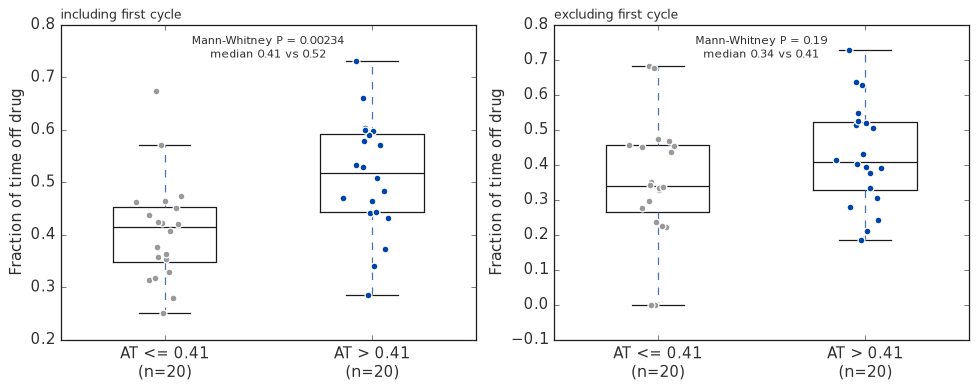

In [16]:
thr = float(bench["AT_Score"].median()); bench["AT_group"] = np.where(bench["AT_Score"] > thr, "high", "low")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5)); rows = []
for ax, (ycol, lab) in zip(axs, [("Holiday_all", "including first cycle"), ("Holiday_after_C1", "excluding first cycle")]):
    sub = bench[["AT_group", ycol]].dropna()
    lo_v, hi_v = sub[sub.AT_group == "low"][ycol], sub[sub.AT_group == "high"][ycol]
    u = mannwhitneyu(hi_v, lo_v, alternative="two-sided")
    for k, (vals, c) in enumerate(((lo_v, "#999999"), (hi_v, BLUE))):
        ax.boxplot(vals, positions=[k], widths=.5, showfliers=False, boxprops=dict(color="k"), medianprops=dict(color="k"))
        ax.scatter(np.random.default_rng(0).normal(k, .06, len(vals)), vals, color=c, s=30, zorder=3, edgecolor="w")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["AT <= %.2f\n(n=%d)" % (thr, len(lo_v)), "AT > %.2f\n(n=%d)" % (thr, len(hi_v))])
    ax.set_ylabel("Fraction of time off drug"); ax.set_title(lab, fontsize=10, loc="left")
    ax.text(0.5, 0.97, "Mann-Whitney P = %.3g\nmedian %.2f vs %.2f" % (u.pvalue, lo_v.median(), hi_v.median()), transform=ax.transAxes, ha="center", va="top", fontsize=9)
    rows.append({"Endpoint": ycol, "Threshold": thr, "n_low": len(lo_v), "n_high": len(hi_v), "median_low": lo_v.median(), "median_high": hi_v.median(), "Mann-Whitney P": u.pvalue})
fig.tight_layout(); fig.savefig(f"{OUT}/holiday_bruchovsky_group_boxplots.png", dpi=150); plt.show()
group_df = pd.DataFrame(rows); print(group_df.round(4).to_string(index=False)); group_df.to_csv(f"{OUT}/holiday_bruchovsky_group_comparison.csv", index=False)

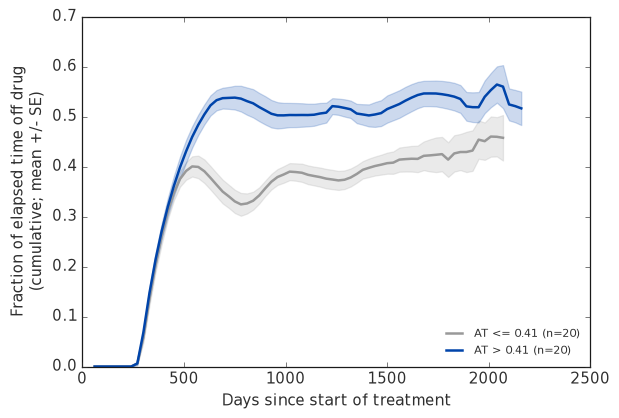

In [17]:
def cumulative_off_fraction(pid, grid):
    d = LoadPatientData(pid, data_path).dropna(subset=["DrugConcentration"]).sort_values("Time")
    t = d.Time.to_numpy(float); g = d.DrugConcentration.to_numpy(float)
    off_len = np.where(g[:-1] == 0, np.diff(t), 0.0); cum = np.concatenate([[0], np.cumsum(off_len)])
    out = np.full(len(grid), np.nan)
    for i, s in enumerate(grid):
        if s <= t[-1] and s > 0: out[i] = np.interp(s, t, cum) / s
    return out

grid = np.arange(60, 4000, 30); MIN_AT_RISK = 5
fig, ax = plt.subplots(figsize=(7, 4.8))
for grp, c in (("low", "#999999"), ("high", BLUE)):
    ids = bench[bench.AT_group == grp].PatientId.tolist()
    M = np.array([cumulative_off_fraction(int(i), grid) for i in ids]); n_obs = np.isfinite(M).sum(0); ok = n_obs >= MIN_AT_RISK
    mean = np.nanmean(M, 0); se = np.nanstd(M, 0, ddof=1) / np.sqrt(np.maximum(n_obs, 1))
    ax.plot(grid[ok], mean[ok], color=c, lw=2, label="AT %s (n=%d)" % ("> %.2f" % thr if grp == "high" else "<= %.2f" % thr, len(ids)))
    ax.fill_between(grid[ok], (mean - se)[ok], (mean + se)[ok], color=c, alpha=.2)
ax.set_xlabel("Days since start of treatment"); ax.set_ylabel("Fraction of elapsed time off drug\n(cumulative; mean +/- SE)"); ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT}/holiday_bruchovsky_cumulative_curves.png", dpi=150); plt.show()